# Lab Assignment 9 — 3D CNN for Fall Detection (URFD)

## 1. Install dependencies

In [1]:
%pip install -q kagglehub opencv-python scikit-learn matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import random
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793557509.679495   34228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793557509.680065   34228 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793557509.740808   34228 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793557511.434400   34228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793557511.434776   34228 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0
Available GPUs: []


E0000 00:00:1793557512.647499   34228 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793557512.647967   34324 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793557512.666002   34228 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## 2. Download dataset using KaggleHub
This cell downloads the latest available dataset version. KaggleHub may require Kaggle authentication depending on your environment.

In [3]:
DATASET_DIR = Path.home() / ".cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb"
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Cached Kaggle dataset was not found at {DATASET_DIR}."
    )

print("Dataset downloaded successfully.")
print("Path to dataset files:", DATASET_DIR)
print("Directory exists:", DATASET_DIR.exists())

Dataset downloaded successfully.
Path to dataset files: /home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb
Directory exists: True


### 2.1 Explore the downloaded directory

In [4]:
sequence_dirs = sorted(p for p in DATASET_DIR.iterdir() if p.is_dir())
print("Sequence directories:", len(sequence_dirs))
for sequence_dir in sequence_dirs[:10]:
    print(sequence_dir.name, "| frames:", len(list(sequence_dir.glob("*.png"))))

Sequence directories: 70
adl-01-cam0-rgb | frames: 150
adl-02-cam0-rgb | frames: 180
adl-03-cam0-rgb | frames: 180
adl-04-cam0-rgb | frames: 150
adl-05-cam0-rgb | frames: 180
adl-06-cam0-rgb | frames: 230
adl-07-cam0-rgb | frames: 180
adl-08-cam0-rgb | frames: 180
adl-09-cam0-rgb | frames: 150
adl-10-cam0-rgb | frames: 300


## Task 1 — Data acquisition and exploration

### 3. Find video files and infer labels

In [5]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}

sequence_paths = sorted(
    p for p in DATASET_DIR.iterdir()
    if p.is_dir() and any(frame.suffix.lower() in IMAGE_EXTENSIONS for frame in p.iterdir())
)

print("Total image sequences discovered:", len(sequence_paths))
for sequence in sequence_paths[:20]:
    print(sequence)

Total image sequences discovered: 70
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-01-cam0-rgb
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-02-cam0-rgb
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-03-cam0-rgb
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-04-cam0-rgb
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-05-cam0-rgb
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-06-cam0-rgb
/home/sambhav/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-07

In [6]:
def infer_label(path):
    text = "_".join(part.lower() for part in path.parts)
    text = re.sub(r"[^a-z0-9]+", "_", text)

    # Check non-fall labels first to avoid matching "fall" inside "nonfall".
    if re.search(r"adl|non_?fall|no_?fall|normal|activities_of_daily_living", text):
        return 0
    if re.search(r"fall|falling", text):
        return 1
    return np.nan

manifest = pd.DataFrame({"sequence_path": [str(p) for p in sequence_paths]})
manifest["label"] = manifest["sequence_path"].apply(lambda x: infer_label(Path(x)))
manifest["class_name"] = manifest["label"].map({0: "Non-Fall / ADL", 1: "Fall"})

print("Discovered videos:", len(manifest))
print("Videos with unknown labels:", int(manifest["label"].isna().sum()))
display(manifest.head(30))

Discovered videos: 70
Videos with unknown labels: 0


,sequence_path,label,class_name
0,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
1,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
2,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
3,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
4,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
5,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
6,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
7,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
8,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL
9,/home/sambhav/.cache/kagglehub/datasets/shahli...,0,Non-Fall / ADL


### 3.1 Correct labels manually if needed

Inspect the manifest above. If labels are missing or incorrect, create a mapping from each video filename to `1` (Fall) or `0` (Non-Fall / ADL). The example below is intentionally commented out; edit it to match your dataset before running.

Label distribution:


,video_count
class_name,
Non-Fall / ADL,40
Fall,30


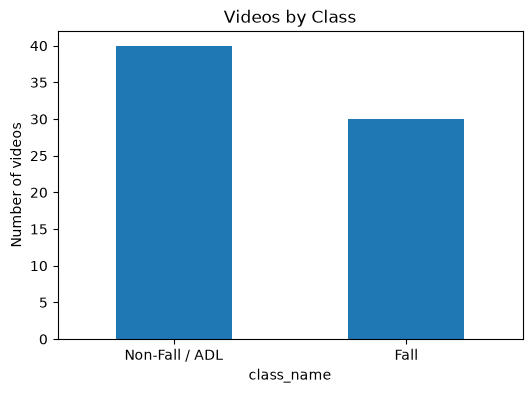

In [7]:
# Example only — uncomment and replace with your actual filenames:
# manual_labels = {
#     "fall_sequence_01.avi": 1,
#     "adl_sequence_01.avi": 0,
# }
#
# manifest["label"] = manifest.apply(
#     lambda row: manual_labels.get(Path(row["video_path"]).name, row["label"]),
#     axis=1
# )

manifest = manifest.dropna(subset=["label"]).copy()
manifest["label"] = manifest["label"].astype(int)
manifest["class_name"] = manifest["label"].map({0: "Non-Fall / ADL", 1: "Fall"})

print("Label distribution:")
display(manifest["class_name"].value_counts().to_frame("video_count"))

if len(manifest):
    manifest["class_name"].value_counts().plot(
        kind="bar", figsize=(6, 4), title="Videos by Class"
    )
    plt.ylabel("Number of videos")
    plt.xticks(rotation=0)
    plt.show()

### 3.2 Check corrupted or unreadable videos

In [8]:
def sequence_is_readable(sequence_path):
    frames = sorted(
    p for p in Path(sequence_path).iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )
    return bool(frames and cv2.imread(str(frames[0])) is not None)

if len(manifest):
    manifest["readable"] = manifest["sequence_path"].apply(sequence_is_readable)
    print("Unreadable sequences:", int((~manifest["readable"]).sum()))
    manifest = manifest[manifest["readable"]].drop(columns="readable").reset_index(drop=True)

print("Sequences retained:", len(manifest))
display(manifest.groupby("class_name").size().to_frame("verified_sequence_count"))

Unreadable sequences: 0
Sequences retained: 70


,verified_sequence_count
class_name,
Fall,30
Non-Fall / ADL,40


### 3.3 Visually inspect normal and fall examples

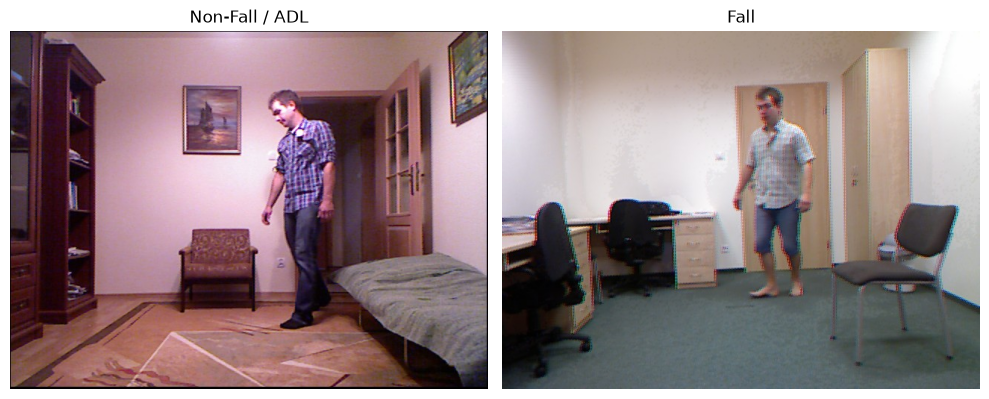

In [9]:
def read_preview_frame(sequence_path, position=0.5):
    frames = sorted(p for p in Path(sequence_path).iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
    if not frames:
        return None
    frame = cv2.imread(str(frames[int((len(frames) - 1) * position)]))
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if frame is not None else None

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label, title in zip(axes, [0, 1], ["Non-Fall / ADL", "Fall"]):
    ax.set_title(title)
    ax.axis("off")
    examples = manifest[manifest["label"] == label]
    if len(examples):
        frame = read_preview_frame(examples.iloc[0]["sequence_path"])
        if frame is not None:
            ax.imshow(frame)
        else:
            ax.text(0.5, 0.5, "Could not read preview", ha="center")
    else:
        ax.text(0.5, 0.5, "No labelled video found", ha="center")
plt.tight_layout()
plt.show()

## Task 2 — Data preprocessing

In [10]:
NUM_FRAMES = 16
IMG_HEIGHT = 112
IMG_WIDTH = 112
CHANNELS = 3
BATCH_SIZE = 2
EPOCHS = 20

def load_video_tensor(sequence_path, training=False):
    frame_paths = sorted(
        p for p in Path(sequence_path).iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )
    total_frames = len(frame_paths)
    if total_frames == 0:
        raise ValueError(f"No readable frames in: {sequence_path}")

    # Temporal jitter: randomly choose a valid starting point during training.
    if training and total_frames > NUM_FRAMES:
        start = random.randint(0, total_frames - NUM_FRAMES)
        indices = np.linspace(start, total_frames - 1, NUM_FRAMES).astype(int)
    else:
        indices = np.linspace(0, total_frames - 1, NUM_FRAMES).astype(int)

    frames = []
    for frame_idx in indices:
        frame = cv2.imread(str(frame_paths[int(frame_idx)]))
        ok = frame is not None

        if not ok or frame is None:
            if frames:
                frames.append(frames[-1].copy())
                continue
            raise ValueError(f"Could not decode frame {frame_idx}: {sequence_path}")

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_AREA)
        frames.append(frame)

    video = np.stack(frames).astype(np.float32) / 255.0

    if training:
        if random.random() < 0.5:
            video = video[:, :, ::-1, :]
        if random.random() < 0.3:
            brightness_delta = random.uniform(-0.08, 0.08)
            video = np.clip(video + brightness_delta, 0.0, 1.0)

    return video

Video tensor shape: (16, 112, 112, 3)
Pixel range: 0.0 to 1.0


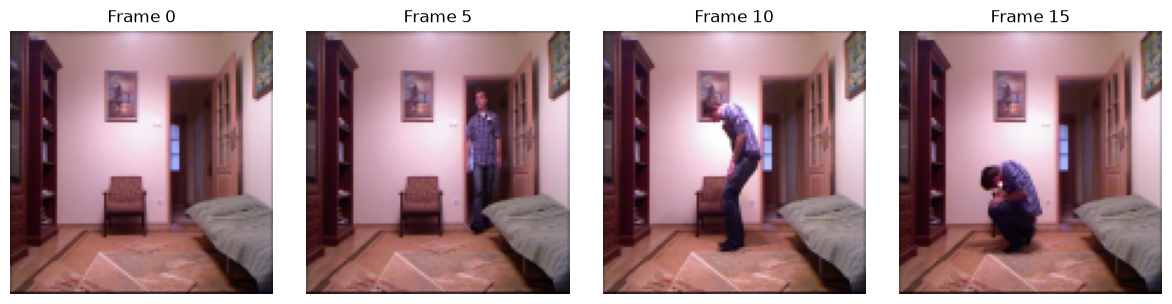

In [11]:
if len(manifest):
    sample_video = load_video_tensor(manifest.iloc[0]["sequence_path"])
    print("Video tensor shape:", sample_video.shape)
    print("Pixel range:", float(sample_video.min()), "to", float(sample_video.max()))

    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    for i, ax in enumerate(axes):
        frame_idx = int(i * (NUM_FRAMES - 1) / 3)
        ax.imshow(sample_video[frame_idx])
        ax.set_title(f"Frame {frame_idx}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 4.1 Split into training, validation and testing sets

The assignment specifies 70% training, 15% validation and 15% testing. Stratified splitting preserves class proportions as far as the small dataset allows. With only around 70 sequences, individual split metrics may be unstable.

In [12]:
if len(manifest) < 10:
    raise ValueError("Too few labelled, readable videos. Check the dataset path and labels.")

if manifest["label"].nunique() != 2:
    raise ValueError("Both classes (Fall and Non-Fall/ADL) must be present before splitting.")

train_df, temp_df = train_test_split(
    manifest,
    test_size=0.30,
    random_state=SEED,
    stratify=manifest["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(
        f"{split_name}: {len(split_df)} videos | "
        f"class counts: {split_df['label'].value_counts().to_dict()}"
    )

Training: 49 videos | class counts: {0: 28, 1: 21}
Validation: 10 videos | class counts: {0: 6, 1: 4}
Testing: 11 videos | class counts: {0: 6, 1: 5}


### 4.2 Handle class imbalance with class weights

In [13]:
class_counts = train_df["label"].value_counts().to_dict()
class_weight = {
    int(class_id): len(train_df) / (2.0 * count)
    for class_id, count in class_counts.items()
}
print("Class weights:", class_weight)

Class weights: {0: 0.875, 1: 1.1666666666666667}


## Task 3 — 3D CNN model

The 3D CNN uses 3D convolutions to learn spatial and temporal patterns from video clips. The sigmoid output gives the probability that a clip contains a fall.

In [14]:
from tensorflow.keras import layers, models

def build_3d_cnn():
    inputs = layers.Input(
        shape=(NUM_FRAMES, IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    )

    x = layers.Conv3D(16, (3, 3, 3), padding="same", activation="relu")(inputs)
    x = layers.MaxPool3D((1, 2, 2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPool3D((2, 2, 2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv3D(64, (3, 3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPool3D((2, 2, 2))(x)
    x = layers.BatchNormalization()(x)

    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs, name="URFD_3D_CNN")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

model = build_3d_cnn()
model.summary()

Model: "URFD_3D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16, 112, 112,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 56, 56, 16) │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 28, 28, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 14, 14, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,201 (293.75 KB)

 Trainable params: 74,977 (292.88 KB)

 Non-trainable params: 224 (896.00 B)

### 5.1 Batch video generator
Videos are decoded only when a batch is requested, instead of loading every video tensor into memory at once.

In [15]:
class VideoSequence(tf.keras.utils.Sequence):
    def __init__(self, dataframe, batch_size=BATCH_SIZE, training=False, shuffle=False):
        super().__init__()
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.batch_size = batch_size
        self.training = training
        self.shuffle = shuffle
        self.indices = np.arange(len(self.dataframe))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        batch = self.dataframe.iloc[batch_indices]

        videos, labels = [], []
        for _, row in batch.iterrows():
            videos.append(load_video_tensor(row["sequence_path"], training=self.training))
            labels.append(float(row["label"]))

        return np.stack(videos).astype(np.float32), np.asarray(labels, dtype=np.float32)

train_seq = VideoSequence(train_df, training=True, shuffle=True)
val_seq = VideoSequence(val_df, training=False)
test_seq = VideoSequence(test_df, training=False)

print("Train batches:", len(train_seq))
print("Validation batches:", len(val_seq))
print("Test batches:", len(test_seq))

Train batches: 25
Validation batches: 5
Test batches: 6


In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_urfd_3d_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1793557516.455127   34228 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.



 1/25 ━━━━━━━━━━━━━━━━━━━━ 1:24 4s/step - accuracy: 0.5000 - auc: 1.0000 - loss: 0.6922


 2/25 ━━━━━━━━━━━━━━━━━━━━ 12s 551ms/step - accuracy: 0.2500 - auc: 0.5000 - loss: 0.7890


 3/25 ━━━━━━━━━━━━━━━━━━━━ 10s 482ms/step - accuracy: 0.3333 - auc: 0.2500 - loss: 0.7880


 4/25 ━━━━━━━━━━━━━━━━━━━━ 10s 505ms/step - accuracy: 0.5000 - auc: 0.4000 - loss: 0.7371

... (288 outputs left out)


23/25 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.7778 - auc: 0.8421 - loss: 0.5039


24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.7447 - auc: 0.8231 - loss: 0.5145


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.7551 - auc: 0.8376 - loss: 0.4984


25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 362ms/step - accuracy: 0.7551 - auc: 0.8376 - loss: 0.4984 - val_accuracy: 0.6000 - val_auc: 1.0000 - val_loss: 0.7197 - learning_rate: 2.5000e-05


### 5.2 Training curves

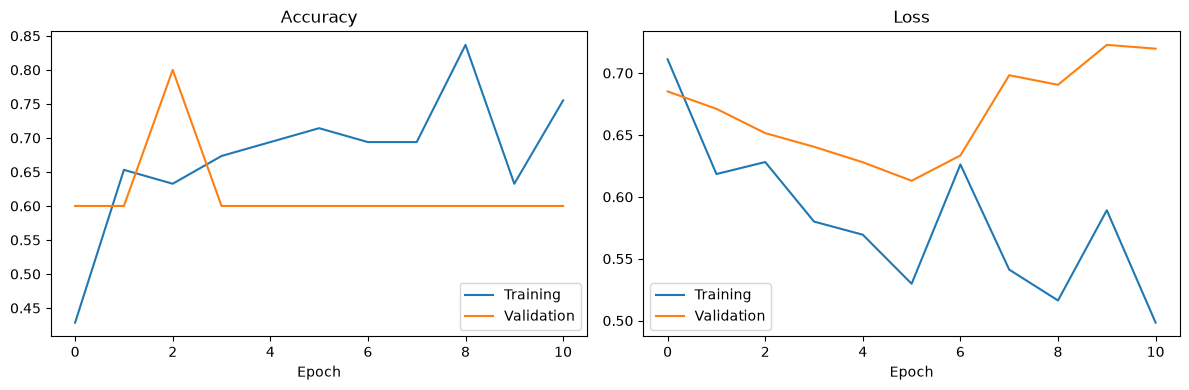

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.3 Evaluate on the test set

Fall is the positive class (`1`). AUROC is calculated from predicted probabilities. If the test set contains only one class, AUROC is undefined.

In [18]:
y_true = test_df["label"].to_numpy().astype(int)
y_prob = model.predict(test_seq, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

test_auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUROC"],
    "Value": [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0),
        test_auc
    ]
})
display(metrics_df)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Fall / ADL", "Fall"],
    zero_division=0
))


1/6 ━━━━━━━━━━━━━━━━━━━━ 1s 378ms/step


2/6 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step


3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step


4/6 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step


5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step


6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 254ms/step


,Metric,Value
0,Accuracy,0.545455
1,Precision,0.000000
2,Recall,0.000000
3,F1-score,0.000000
4,AUROC,0.800000


                precision    recall  f1-score   support

Non-Fall / ADL       0.55      1.00      0.71         6
          Fall       0.00      0.00      0.00         5

      accuracy                           0.55        11
     macro avg       0.27      0.50      0.35        11
  weighted avg       0.30      0.55      0.39        11



### 5.4 Confusion matrix

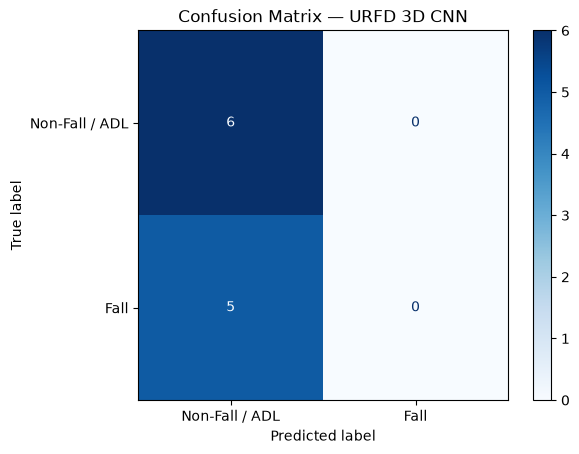

Rows = actual class; columns = predicted class


In [19]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Fall / ADL", "Fall"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix — URFD 3D CNN")
plt.show()
print("Rows = actual class; columns = predicted class")

### 5.5 ROC curve

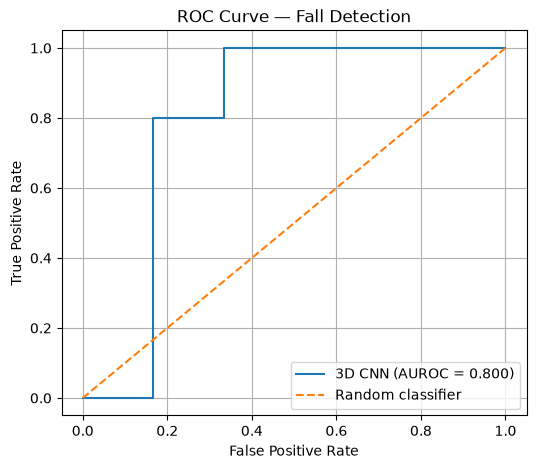

In [20]:
if len(np.unique(y_true)) == 2:
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"3D CNN (AUROC = {test_auc:.3f})")
    plt.plot([0, 1], [0, 1], "--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve — Fall Detection")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("ROC curve unavailable because the test set contains only one class.")

### 5.6 Inspect misclassified videos

In [21]:
errors = test_df.copy()
errors["actual_label"] = y_true
errors["predicted_label"] = y_pred
errors["fall_probability"] = y_prob
errors["actual_class"] = errors["actual_label"].map({0: "Non-Fall / ADL", 1: "Fall"})
errors["predicted_class"] = errors["predicted_label"].map({0: "Non-Fall / ADL", 1: "Fall"})

misclassified = errors[errors["actual_label"] != errors["predicted_label"]]
print("Misclassified videos:", len(misclassified))
display(misclassified[
    ["sequence_path", "actual_class", "predicted_class", "fall_probability"]
])

Misclassified videos: 5


,sequence_path,actual_class,predicted_class,fall_probability
67,/home/sambhav/.cache/kagglehub/datasets/shahli...,Fall,Non-Fall / ADL,0.389294
46,/home/sambhav/.cache/kagglehub/datasets/shahli...,Fall,Non-Fall / ADL,0.374312
43,/home/sambhav/.cache/kagglehub/datasets/shahli...,Fall,Non-Fall / ADL,0.384706
53,/home/sambhav/.cache/kagglehub/datasets/shahli...,Fall,Non-Fall / ADL,0.383232
57,/home/sambhav/.cache/kagglehub/datasets/shahli...,Fall,Non-Fall / ADL,0.386511


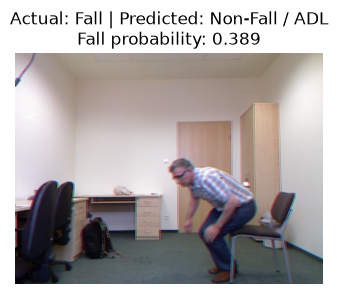

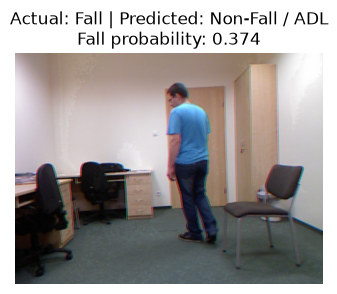

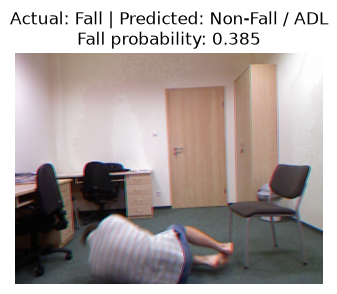

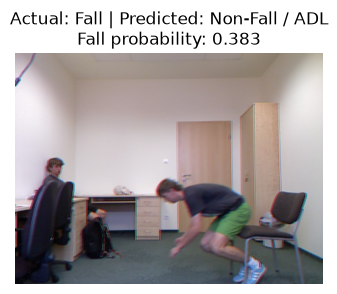

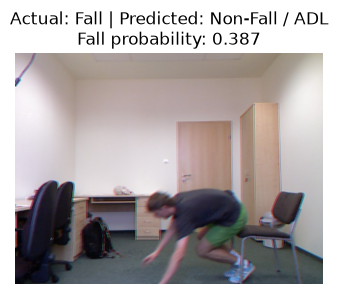

In [22]:
for _, row in misclassified.iterrows():
    frame = read_preview_frame(row["sequence_path"])
    if frame is not None:
        plt.figure(figsize=(5, 3))
        plt.imshow(frame)
        plt.title(
            f"Actual: {row['actual_class']} | Predicted: {row['predicted_class']}\n"
            f"Fall probability: {row['fall_probability']:.3f}"
        )
        plt.axis("off")
        plt.show()

## 6. Save model and results

In [23]:
model.save("urfd_3d_cnn_final.keras")
metrics_df.to_csv("urfd_3d_cnn_test_metrics.csv", index=False)
errors.to_csv("urfd_test_predictions.csv", index=False)
print("Saved: urfd_3d_cnn_final.keras")
print("Saved: urfd_3d_cnn_test_metrics.csv")
print("Saved: urfd_test_predictions.csv")

Saved: urfd_3d_cnn_final.keras
Saved: urfd_3d_cnn_test_metrics.csv
Saved: urfd_test_predictions.csv
